# Interactive tutorial

This notebook solves two small stationary mean field games using only the public
`benchmfg` API:

1. **OMD on the beach bar** (1D Lasry-Lions chain).
2. **Fictitious Play on kinetic congestion** (5x5 grid).

For each one we print the configuration, run the solver, plot the exploitability
decay, the final mean field and the final policy, and animate all three over the
iterations.

Run it locally with `pip install bench-mfg-suite jupyter`. Change the overrides to try
another algorithm (`algorithm=omd`, `algorithm=damped_fixed_point`, `algorithm=pi`)
or other hyperparameters.

In [1]:
import benchmfg as bmfg

%matplotlib inline

## Example 1: OMD on the beach bar

The **Lasry-Lions chain** is a 1D version of the *beach bar* problem.
Agents stand on a chain of states and the bar is in the middle. Each agent wants to be
near the bar (`center_attraction`) but dislikes crowds (`crowd_penalty_coefficient`)
and pays a cost to move (`movement_penalty`). The actions are left, stay and right.

### Configure the environment and the algorithm

In [2]:
overrides = [
    "environment=lasry_lions_chain",
    "algorithm=omd",
    "algorithm.omd.num_iterations=150",
    "algorithm.omd.learning_rate=0.02",
    "algorithm.omd.temperature=0.2",
    "device=cpu",
]
cfg = bmfg.load_config(overrides)

In [3]:
bmfg.print_config_env(cfg)

name: LasryLionsChain
grid:
  is_grid: false
num_states: 7
num_actions: 3
num_noises: 3
horizon: 100
gamma: 0.9
dynamics:
  is_noisy: true
  noise_probabilities:
  - 0.025
  - 0.95
  - 0.025
reward:
  lasry_lions:
    crowd_penalty_coefficient: 40
    movement_penalty: 2
    center_attraction: 3
initial_distribution:
  type: uniform
  concentration_state: 5
  concentration_ratio: 0.8



In [4]:
bmfg.print_config_algo(cfg)

_target_: OMD
omd:
  use_python: false
  num_iterations: 150
  verbose: true
  early_stopping_enabled: false
  initialization_type: PSO_uniform
  init_policy_temp: 0.2
  learning_rate: 0.02
  temperature: 0.2



The initial policy is random and seeded by `experiment.random_seed` (default 42).
OMD with a fixed learning rate can get stuck from some starting points: try
`"experiment.random_seed=10"` to see it, then a smaller learning rate to recover.

### Run the solver

`bmfg.History()` records the exploitability, mean field and policy at every iteration.
Pass it to `solver.eval` as the `logger`.

In [5]:
environment, initial_policy = bmfg.make_environment(cfg)
solver = bmfg.make_solver(cfg, environment=environment, initial_policy=initial_policy)

history = bmfg.History()
policy, mean_field, exploitabilities = solver.eval(logger=history)
print(f"Final exploitability: {exploitabilities[-1]:.4g}")

Running OMD (temperature: 0.2):   0%|          | 0/150 [00:00<?, ?it/s]

Running OMD (temperature: 0.2):  49%|████▊     | 73/150 [00:00<00:00, 729.60it/s]

Running OMD (temperature: 0.2): 100%|██████████| 150/150 [00:00<00:00, 1400.61it/s]

Final exploitability: 0.0003815


### Exploitability, final mean field and final policy

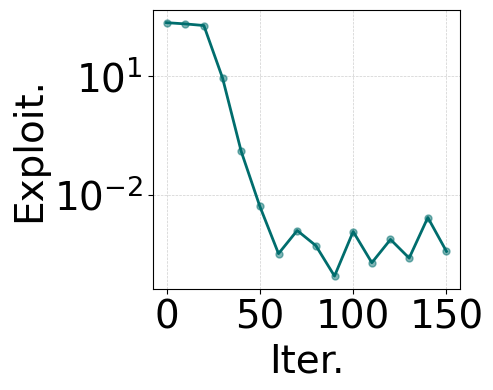

In [6]:
fig = bmfg.plot_exploitability(exploitabilities, log_scale=True, return_fig=True)

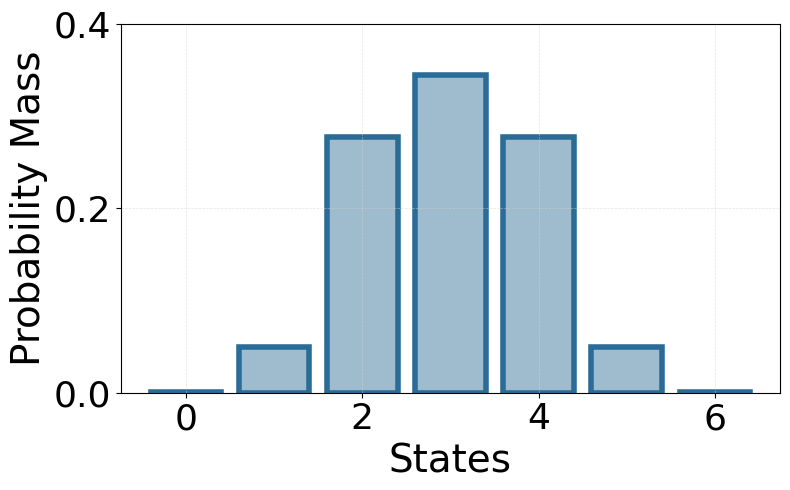

In [7]:
fig = bmfg.plot_mean_field(mean_field, is_grid=False, return_fig=True)

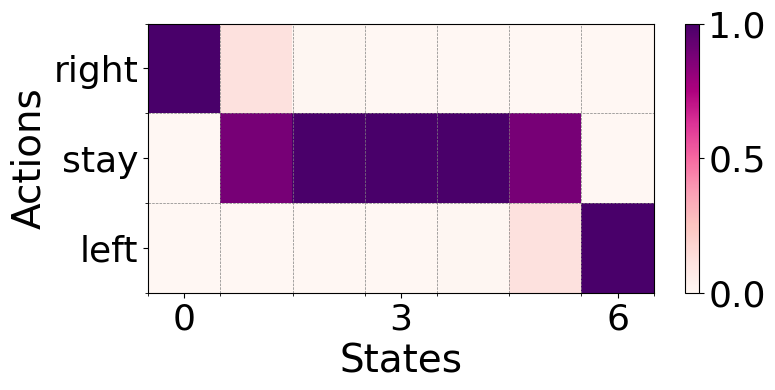

In [8]:
actions = ["left", "stay", "right"]
fig = bmfg.plot_policy(policy, action_labels=actions, return_fig=True)

### Animation over the iterations

`bmfg.plot_gif` writes one GIF frame per iteration (`every=5` keeps every fifth one),
and `bmfg.show_gifs` shows several GIFs side by side.


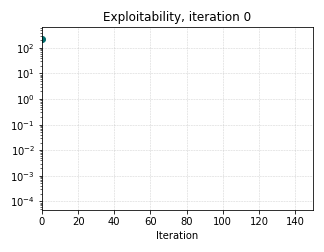
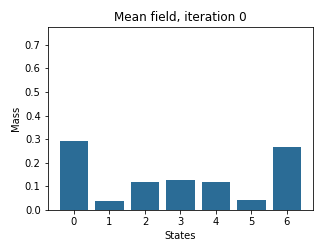
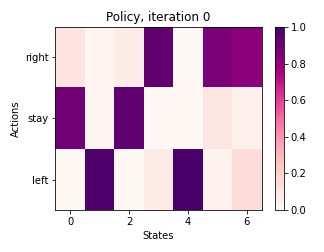

In [9]:
gifs = [
    bmfg.plot_gif(history.exploitabilities, "gifs/omd_expl.gif", kind="exploitability", every=5),
    bmfg.plot_gif(history.mean_fields, "gifs/omd_mf.gif", kind="mean_field", every=5),
    bmfg.plot_gif(history.policies, "gifs/omd_pi.gif", kind="policy", every=5, action_labels=actions),
]
bmfg.show_gifs(*gifs)

## Example 2: Fictitious Play on kinetic congestion

In **kinetic congestion** agents on a 5x5 grid want to reach the target cell in the
top-right corner (`target_state: 24`). Crowding does not cost reward directly: instead,
a move into a cell fails more often the fuller that cell is (`capacity_threshold`).
Moving costs `movement_cost`. The actions are up, right, down, left and stay.

**Fictitious Play** is `algorithm=damped_fixed_point` with
`lambda_schedule: fictitious_play`: it averages the best responses over the iterations,
so exploitability decays roughly like 1/k. The policy it reports is that average.

In [10]:
cfg = bmfg.load_config([
    "environment=kinetic_congestion",
    "algorithm=damped_fixed_point",
    "algorithm.dampedfp.lambda_schedule=fictitious_play",
    "algorithm.dampedfp.num_iterations=50",
    "device=cpu",
])
bmfg.print_config_env(cfg)

name: KineticCongestion
grid:
  is_grid: true
  dimension:
  - 5
  - 5
num_states: 25
num_actions: 5
num_noises: 100
horizon: 100
gamma: 0.9
dynamics:
  is_noisy: true
  noise_probabilities: []
reward:
  kinetic_congestion:
    target_state: 24
    movement_cost: 0.1
    capacity_threshold: 0.18
initial_distribution:
  type: uniform
  concentration_state: 0
  concentration_ratio: 0.8



In [11]:
bmfg.print_config_algo(cfg)

_target_: DampedFP
dampedfp:
  use_python: false
  num_iterations: 50
  convergence_tolerance: 1.0e-06
  verbose: true
  num_transition_steps: 20
  early_stopping_enabled: false
  initialization_type: PSO_uniform
  init_policy_temp: 0.2
  lambda_schedule: fictitious_play
  damped_constant: 0.2
  best_response: exact
  ppo_total_timesteps: 10000
  ppo_n_steps: 128
  ppo_batch_size: 64
  ppo_learning_rate: 0.0003
  ppo_n_epochs: 10
  ppo_seed: 0
  ppo_reset_uniform_eps: 0.1
  ppo_episode_length: null
  ppo_normalize_reward: true
  ppo_device: cpu
  ppo_n_envs: 1
  ppo_warm_start: false
  dqn_total_timesteps: 10000
  dqn_learning_rate: 0.001
  dqn_buffer_size: 10000
  dqn_learning_starts: 100
  dqn_batch_size: 32
  dqn_train_freq: 1
  dqn_gradient_steps: 1
  dqn_exploration_fraction: 0.1
  dqn_exploration_final_eps: 0.05
  dqn_seed: 0
  dqn_reset_uniform_eps: 0.1
  dqn_episode_length: null
  dqn_normalize_reward: false
  dqn_device: cpu
  dqn_n_envs: 1
  dqn_warm_start: true



In [12]:
environment, initial_policy = bmfg.make_environment(cfg)
solver = bmfg.make_solver(cfg, environment=environment, initial_policy=initial_policy)

history = bmfg.History()
policy, mean_field, exploitabilities = solver.eval(logger=history)
print(f"Final exploitability: {exploitabilities[-1]:.4g}")

Running:   0%|          | 0/50 [00:00<?, ?it/s]

Running:   2%|▏         | 1/50 [00:00<00:06,  7.39it/s]

Running:   6%|▌         | 3/50 [00:00<00:03, 13.64it/s]

Running:  10%|█         | 5/50 [00:00<00:02, 16.13it/s]

Running:  14%|█▍        | 7/50 [00:00<00:02, 16.95it/s]

Running:  18%|█▊        | 9/50 [00:00<00:02, 17.25it/s]

... (18 outputs left out)

Running:  94%|█████████▍| 47/50 [00:03<00:00, 13.41it/s]

Running:  98%|█████████▊| 49/50 [00:03<00:00, 13.05it/s]

Running: 100%|██████████| 50/50 [00:03<00:00, 14.35it/s]

Final exploitability: 0.0765


### Exploitability, final mean field and final policy

On a grid, pass `grid_dim` (from the config) to the plotting functions.

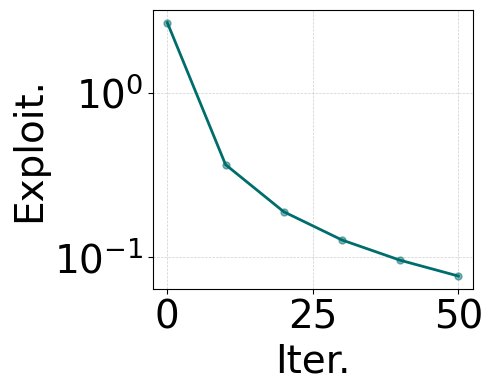

In [13]:
grid_dim = tuple(cfg.environment.grid.dimension)
fig = bmfg.plot_exploitability(exploitabilities, log_scale=True, return_fig=True)

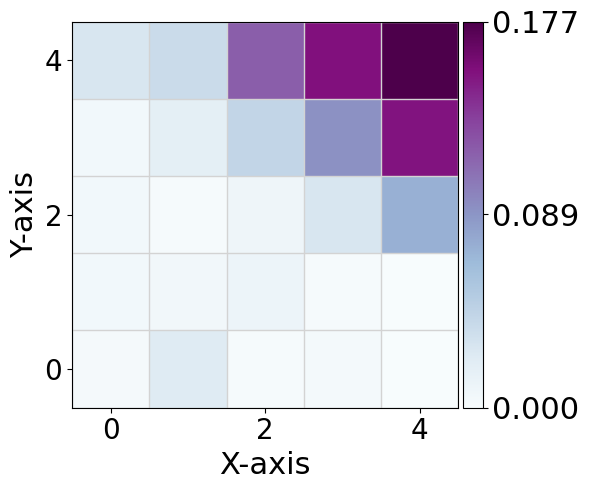

In [14]:
fig = bmfg.plot_mean_field(mean_field, is_grid=True, grid_dim=grid_dim, return_fig=True)

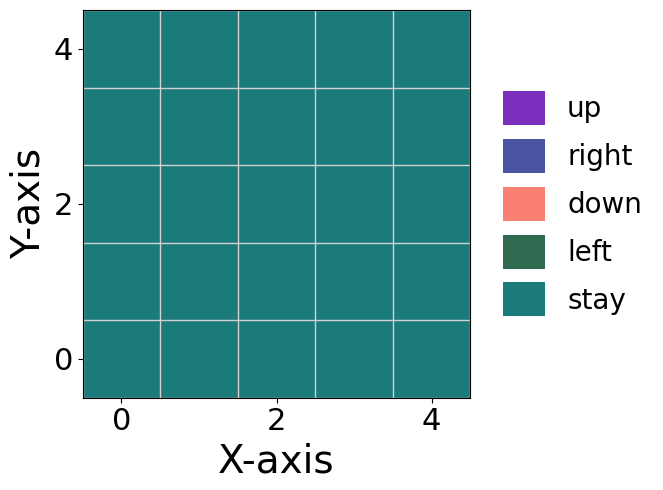

In [15]:
fig = bmfg.plot_policy(policy, grid_dim=grid_dim, return_fig=True)

### Animation over the iterations

In the policy GIF each cell shows its most likely action (↑ → ↓ ← or · for stay),
colored by that action's probability.

In the first iterations agents head up and right toward the target. Once the target
cell holds `capacity_threshold` of the mass, every move into it is rejected, so moving
only costs `movement_cost`: at the equilibrium everyone else stays where they are.


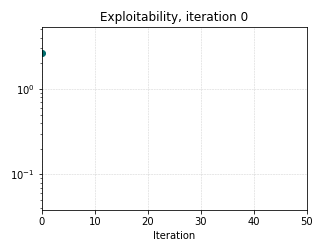
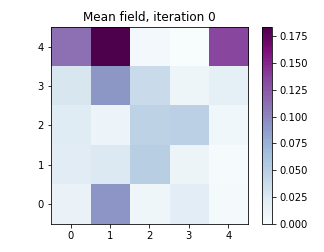
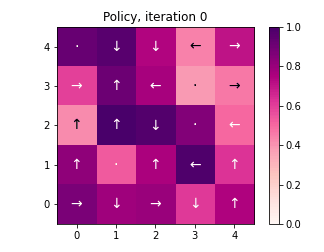

In [16]:
gifs = [
    bmfg.plot_gif(history.exploitabilities, "gifs/fp_expl.gif", kind="exploitability", every=2),
    bmfg.plot_gif(history.mean_fields, "gifs/fp_mf.gif", kind="mean_field", every=2, grid_dim=grid_dim),
    bmfg.plot_gif(history.policies, "gifs/fp_pi.gif", kind="policy", every=2, grid_dim=grid_dim),
]
bmfg.show_gifs(*gifs)